# 05 · Shot noise

All earlier results use **exact** similarities from a simulator. A real quantum computer cannot read a similarity directly: it runs the circuit *n* times ("shots") and counts how often it returns the all-zero outcome. The fraction of zeros estimates the similarity K, with a random error that shrinks as n grows:

  estimate = Binomial(n, K) / n,  error SD = √(K(1 − K) / n)

This notebook asks: **do the findings survive realistic measurement noise?**

| Design choice | Value |
|---|---|
| Shots per similarity | 100, 1,000, 10,000 |
| Settings | clean, and the strongest level of each damage (missing 30 %, noise 0.3, labels 15 %) |
| Folds | the same 25 folds and damage seeds as `03_experiments` |
| Diagonal | stays exactly 1 (a state compared with itself always returns all zeros) |
| Valid kernel | a noisy training kernel can get small negative eigenvalues; they are set to 0 (eigenvalue clipping) before the SVM, and the size of the fix is recorded |
| Quantum model, version 1 | **c re-tuned**: the inner loop chooses c and C on the noisy kernels |
| Quantum model, version 2 | **ideal c kept**: c is the one chosen without shot noise in `03_experiments`; only C is tuned |

The classical models have no shot noise, so they are read from `results/runs/` unchanged. Output: one fold-score file per dataset in `results/shots/` (about 10–20 minutes in total). The test rows are not used.

## 0 · Setup

In [ ]:
import json, time, zlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.svm import SVC
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import get_scorer

from paths import RESULTS
from quantum_kernel import load_ready, get_states, kernel_from_states
from classical_models import SEEDS, SCORING
from corruption import corrupt_training, corruption_seed, noise_columns

DATASETS = ["german_credit", "concrete", "water_potability", "steel_faults",
            "phoneme", "magic_telescope", "bank_marketing", "electricity"]
SHORT = {"german_credit": "German", "concrete": "Concrete", "water_potability": "Water", "steel_faults": "Steel",
         "phoneme": "Phoneme", "magic_telescope": "MAGIC", "bank_marketing": "Bank", "electricity": "Electricity"}
BANDWIDTHS = [0.01, 0.025, 0.05, 0.1, 0.25, 0.5, 0.75, 1.0]
C_GRID = [0.1, 1, 10]#SVM C
SHOTS = [100, 1000, 10000]
SETTINGS = [("clean", 0.0), ("missing", 0.3), ("noise", 0.3), ("labels", 0.15)]
SCORERS = {k: get_scorer(v) for k, v in SCORING.items()}

RUNS, OUT, ANALYSIS = RESULTS / "runs", RESULTS / "shots", RESULTS / "analysis"
OUT.mkdir(parents=True, exist_ok=True)

runs = pd.concat([pd.read_csv(RUNS / f"{n}_folds.csv") for n in DATASETS], ignore_index=True)
runs["level"] = runs.level.round(4)
ideal_c = runs[runs.model == "quantum (c,C tuned)"].set_index(["dataset", "kind", "level", "seed", "fold"]).c
print(f"{len(DATASETS)} datasets x {len(SETTINGS)} settings x {len(SHOTS)} shot counts x 25 folds -> {OUT}")

8 datasets x 4 settings x 3 shot counts x 25 folds -> ./results\shots


## 1 · The shot-noise model

`shot_kernel` turns an exact kernel into one measured with n shots. For the training kernel each pair is measured once (the matrix stays symmetric) and the diagonal stays 1; the kernel between checking and training rows is measured entry by entry. `clip_psd` then removes negative eigenvalues and reports which share of the spectrum it had to change.

The check below uses one dataset: the average estimate equals the exact similarity, and its spread matches √(K(1 − K)/n).

In [2]:
def shot_kernel(K, n, rng, symmetric):
    K = np.clip(K, 0.0, 1.0)
    if not symmetric:
        return rng.binomial(n, K) / n
    upper = np.triu(rng.binomial(n, K) / n, k=1)
    return upper + upper.T + np.eye(len(K))


def clip_psd(K):
    w, V = np.linalg.eigh(K)
    changed = -w[w < 0].sum() / np.abs(w).sum()
    return (V * np.clip(w, 0, None)) @ V.T, changed


X, y, _, _ = load_ready("concrete")
S = get_states(X, X.shape[1], c=0.1)
K = kernel_from_states(S, S)
rng = np.random.default_rng(0)
iu = np.triu_indices(len(K), k=1)
rows = {}
for n in SHOTS:
    draws = np.array([shot_kernel(K, n, rng, True)[iu] for _ in range(50)])
    expected_sd = np.sqrt(K[iu] * (1 - K[iu]) / n)
    rows[f"{n:,} shots"] = {"mean error (should be ≈ 0)": f"{(draws.mean(0) - K[iu]).mean():+.1e}",
                            "measured SD / expected SD": round(draws.std(0, ddof=1).mean() / expected_sd.mean(), 3),
                            "spectrum changed by clipping": f"{clip_psd(shot_kernel(K, n, rng, True))[1]:.2%}"}
pd.DataFrame(rows).T

,mean error (should be ≈ 0),measured SD / expected SD,spectrum changed by clipping
100 shots,-2.1e-05,0.995,16.24%
"1,000 shots",+5.8e-06,0.994,5.87%
"10,000 shots",-1.1e-07,0.996,1.68%


## 2 · One dataset

For every fold and setting, the exact kernels are rebuilt exactly as in `03_experiments` (same damage seeds), then measured with each shot count. Each fold stores the quantum score at every fixed c, the re-tuned model and the ideal-c model.

In [3]:
def tune_C(K, y, inner):
    scores = {C: np.mean([SCORERS["auc"](SVC(kernel="precomputed", C=C, class_weight="balanced")
                                         .fit(K[np.ix_(a, a)], y[a]), K[np.ix_(b, a)], y[b]) for a, b in inner])
              for C in C_GRID}
    best = max(scores, key=scores.get)
    return best, scores[best]


def score(K, Kc, y, yc, C):
    model = SVC(kernel="precomputed", C=C, class_weight="balanced").fit(K, y)
    return {k: SCORERS[k](model, Kc, yc) for k in SCORING}


def run_dataset(name):
    out = OUT / f"{name}_shots.csv"
    if out.exists() and pd.read_csv(out).groupby(["kind", "shots", "seed", "fold"]).ngroups == len(SETTINGS) * len(SHOTS) * 25:
        print(f"   already complete - skipped"); return
    out.unlink(missing_ok=True)
    X, y, _, _ = load_ready(name)
    y, q, cols = y.astype(int), X.shape[1], noise_columns(name)
    clean_states = {c: get_states(X, q, c=c) for c in BANDWIDTHS}
    clean_kernels = {c: kernel_from_states(S, S) for c, S in clean_states.items()}
    rows = []
    for kind, level in SETTINGS:
        for seed in SEEDS:
            for fold, (learn, check) in enumerate(StratifiedKFold(5, shuffle=True, random_state=seed).split(X, y)):
                if kind == "clean":
                    X_l, y_l = X[learn], y[learn]
                else:
                    X_l, y_l = corrupt_training(X[learn], y[learn], kind, level, corruption_seed(name, kind, seed, fold), cols)
                exact = {}
                for c in BANDWIDTHS:
                    if kind in ("clean", "labels"):
                        exact[c] = (clean_kernels[c][np.ix_(learn, learn)], clean_kernels[c][np.ix_(check, learn)])
                    else:
                        S = get_states(X_l, q, c=c)
                        exact[c] = (kernel_from_states(S, S), kernel_from_states(clean_states[c][check], S))
                inner = list(StratifiedKFold(3, shuffle=True, random_state=seed).split(np.zeros(len(y_l)), y_l))
                c_ideal = ideal_c.loc[(name, kind, round(level, 4), seed, fold)]
                for n in SHOTS:
                    rng = np.random.default_rng(zlib.crc32(f"{name}|{kind}|{seed}|{fold}|{n}".encode()))
                    info = {"dataset": name, "kind": kind, "level": level, "seed": seed, "fold": fold, "shots": n}
                    best = (-np.inf, None, None, None)
                    for c in BANDWIDTHS:
                        K, changed = clip_psd(shot_kernel(exact[c][0], n, rng, True))
                        Kc = shot_kernel(exact[c][1], n, rng, False)
                        C, inner_auc = tune_C(K, y_l, inner)
                        sc = score(K, Kc, y_l, y[check], C)
                        rows.append({**info, "model": "quantum (c fixed)", "c": c, "C": C, "inner_auc": inner_auc,
                                     "clipped": changed, **sc})
                        if inner_auc > best[0]:
                            best = (inner_auc, c, C, sc)
                        if c == c_ideal:
                            rows.append({**info, "model": "quantum (ideal c)", "c": c, "C": C, "inner_auc": inner_auc, **sc})
                    rows.append({**info, "model": "quantum (c re-tuned)", "c": best[1], "C": best[2],
                                 "inner_auc": best[0], **best[3]})
    pd.DataFrame(rows).to_csv(out, index=False)

## 3 · Run all eight datasets



In [4]:
total = time.perf_counter()
for name in DATASETS:
    t = time.perf_counter()
    print(SHORT[name], end=" ")
    run_dataset(name)
    print(f"({time.perf_counter() - t:.0f} s)")
print(f"ALL DONE in {(time.perf_counter() - total) / 60:.1f} min")

German (2215 s)
Concrete (285 s)
Water (277 s)
Steel (713 s)
Phoneme (288 s)
MAGIC (292 s)
Bank (742 s)
Electricity (277 s)
ALL DONE in 84.8 min


## 4 · Completeness check

Every dataset: 4 settings × 3 shot counts × 25 folds = 300 fold groups, each with the re-tuned and the ideal-c model.

In [5]:
SH = pd.concat([pd.read_csv(OUT / f"{n}_shots.csv") for n in DATASETS], ignore_index=True)
SH["level"] = SH.level.round(4)
check = SH.groupby("dataset").apply(lambda g: pd.Series({
    "fold groups": f"{g.groupby(['kind', 'shots', 'seed', 'fold']).ngroups}/300",
    "re-tuned rows": int((g.model == "quantum (c re-tuned)").sum()), "ideal-c rows": int((g.model == "quantum (ideal c)").sum()),
    "largest share clipped": f"{g.clipped.max():.2%}"}))
check.rename(index=SHORT)

,fold groups,re-tuned rows,ideal-c rows,largest share clipped
dataset,,,,
Bank,300/300,300,300,16.47%
Concrete,300/300,300,300,16.23%
Electricity,300/300,300,300,16.21%
German,300/300,300,300,16.51%
MAGIC,300/300,300,300,15.26%
Phoneme,300/300,300,300,16.71%
Steel,300/300,300,300,16.69%
Water,300/300,300,300,15.60%


## 5 · Results

The exact (noiseless) quantum and SVM-RBF scores come from `03_experiments`, on the same folds, so every comparison is paired.

### 5.1 Quantum AUC with and without shot noise

In [ ]:
KEY = ["dataset", "kind", "level", "seed", "fold"]#Identifies matching dataset, setting, seed, and fold.
exact = runs[runs.model == "quantum (c,C tuned)"].set_index(KEY).auc.rename("exact")
rbf = runs[runs.model == "svm_rbf"].set_index(KEY).auc.rename("rbf")
label = {"clean": "clean", "missing": "missing 30%", "noise": "noise 0.3", "labels": "labels 15%"}

P = SH[SH.model.isin(["quantum (c re-tuned)", "quantum (ideal c)"])].set_index(KEY).join(exact).join(rbf).reset_index()
tab = P.groupby(["dataset", "kind", "model", "shots"]).auc.mean().unstack("shots")
tab.insert(0, "exact", P.groupby(["dataset", "kind", "model"]).exact.mean())
tab["SVM-RBF"] = P.groupby(["dataset", "kind", "model"]).rbf.mean()
clean_tab = tab.xs("clean", level="kind").xs("quantum (c re-tuned)", level="model").rename(index=SHORT)
clean_tab.columns = ["exact"] + [f"{n:,} shots" for n in SHOTS] + ["SVM-RBF"]
clean_tab.round(3)

,exact,100 shots,"1,000 shots","10,000 shots",SVM-RBF
dataset,,,,,
Bank,0.667,0.655,0.669,0.669,0.649
Concrete,0.925,0.836,0.821,0.900,0.930
Electricity,0.777,0.721,0.744,0.775,0.797
German,0.719,0.681,0.698,0.709,0.732
MAGIC,0.849,0.797,0.789,0.835,0.878
Phoneme,0.849,0.825,0.832,0.837,0.879
Steel,0.747,0.749,0.757,0.739,0.774
Water,0.535,0.485,0.514,0.531,0.627


### 5.2 All eight datasets together

Change of the quantum AUC caused by shot noise (shots − exact), pooled over the 8 datasets with the same Nadeau–Bengio random-effects method as `04_analysis`, and the pooled quantum − SVM-RBF gap under shot noise.

In [7]:
J, RATIO = 25, 0.25
NB = lambda sd: (1 / J + RATIO) * sd ** 2


def meta(est, var):
    est, var = np.asarray(est), np.asarray(var); k = len(est); w = 1 / var
    fe = (w * est).sum() / w.sum()
    tau2 = max(0.0, ((w * (est - fe) ** 2).sum() - (k - 1)) / (w.sum() - (w ** 2).sum() / w.sum()))
    ws = 1 / (var + tau2); re_ = (ws * est).sum() / ws.sum()
    se = max(np.sqrt((ws * (est - re_) ** 2).sum() / ((k - 1) * ws.sum())), np.sqrt(1 / ws.sum()))
    return re_, se, 2 * stats.t.sf(abs(re_ / se), k - 1)


def pooled(diff_col, model, kind, n):
    g = P[(P.model == model) & (P.kind == kind) & (P.shots == n)]
    est = [g[g.dataset == d][diff_col].mean() for d in DATASETS]
    var = [NB(g[g.dataset == d][diff_col].std(ddof=1)) for d in DATASETS]
    re_, se, p = meta(est, var)
    return f"{re_:+.3f} (p = {p:.2f})"


P["shots − exact"] = P.auc - P.exact
P["quantum − RBF"] = P.auc - P.rbf
rows = []
for model in ["quantum (c re-tuned)", "quantum (ideal c)"]:
    for kind in label:
        r = {"model": model, "setting": label[kind]}
        r |= {f"shots − exact, {n:,}": pooled("shots − exact", model, kind, n) for n in SHOTS}
        r |= {f"Q − RBF, {n:,}": pooled("quantum − RBF", model, kind, n) for n in SHOTS}
        rows.append(r)
POOLED_SHOTS = pd.DataFrame(rows).set_index(["model", "setting"])
POOLED_SHOTS.to_csv(ANALYSIS / "shots_pooled.csv")
POOLED_SHOTS

shots − exact, 100 shots − exact, 1,000  \
model                setting                                               
quantum (c re-tuned) clean        -0.033 (p = 0.02)    -0.025 (p = 0.09)   
                     missing 30%  -0.043 (p = 0.02)    -0.019 (p = 0.06)   
                     noise 0.3    -0.030 (p = 0.01)    -0.021 (p = 0.09)   
                     labels 15%   -0.052 (p = 0.01)    -0.040 (p = 0.04)   
quantum (ideal c)    clean        -0.030 (p = 0.06)    -0.021 (p = 0.15)   
                     missing 30%  -0.034 (p = 0.04)    -0.015 (p = 0.18)   
                     noise 0.3    -0.038 (p = 0.04)    -0.032 (p = 0.06)   
                     labels 15%   -0.025 (p = 0.09)    -0.035 (p = 0.05)   

                                 shots − exact, 10,000       Q − RBF, 100  \
model                setting                                                
quantum (c re-tuned) clean           -0.012 (p = 0.07)  -0.060 (p = 0.00)   
                     missing 30%     -0.011 (p = 0.10)  -0.062 (p = 0.01)   
                     noise 0.3       -0.004 (p = 0.37)  -0.050 (p = 0.00)   
                     labels 15%      -0.012 (p = 0.16)  -0.071 (p = 0.00)   
quantum (ideal c)    clean           -0.009 (p = 0.11)  -0.063 (p = 0.01)   
                     missing 30%     -0.011 (p = 0.06)  -0.060 (p = 0.01)   
                     noise 0.3       -0.010 (p = 0.09)  -0.054 (p = 0.01)   
                     labels 15%      -0.008 (p = 0.18)  -0.049 (p = 0.02)   

                                     Q − RBF, 1,000    Q − RBF, 10,000  
model                setting                                            
quantum (c re-tuned) clean        -0.054 (p = 0.01)  -0.035 (p = 0.00)  
                     missing 30%  -0.039 (p = 0.01)  -0.030 (p = 0.01)  
                     noise 0.3    -0.039 (p = 0.01)  -0.022 (p = 0.01)  
                     labels 15%   -0.067 (p = 0.01)  -0.029 (p = 0.04)  
quantum (ideal c)    clean        -0.051 (p = 0.01)  -0.033 (p = 0.00)  
                     missing 30%  -0.041 (p = 0.03)  -0.029 (p = 0.01)  
                     noise 0.3    -0.053 (p = 0.01)  -0.027 (p = 0.01)  
                     labels 15%   -0.060 (p = 0.01)  -0.032 (p = 0.02)

### 5.3 Does shot noise move the chosen bandwidth?

Most chosen c (over the 25 folds) without shot noise and with each shot count, clean data.

In [8]:
tuned_sh = SH[(SH.model == "quantum (c re-tuned)") & (SH.kind == "clean")]
moves = pd.DataFrame({SHORT[d]: {"exact": runs[(runs.dataset == d) & (runs.kind == "clean") & (runs.model == "quantum (c,C tuned)")].c.mode()[0],
                                 **{f"{n:,} shots": tuned_sh[(tuned_sh.dataset == d) & (tuned_sh.shots == n)].c.mode()[0] for n in SHOTS}}
                      for d in DATASETS}).T
moves

,exact,100 shots,"1,000 shots","10,000 shots"
German,0.01,0.025,0.025,0.01
Concrete,0.05,0.100,0.050,0.05
Water,0.25,0.250,0.100,0.25
Steel,0.10,0.100,0.100,0.10
Phoneme,0.10,0.250,0.250,0.25
MAGIC,0.10,0.100,0.100,0.10
Bank,1.00,1.000,1.000,1.00
Electricity,0.05,0.100,0.100,0.05


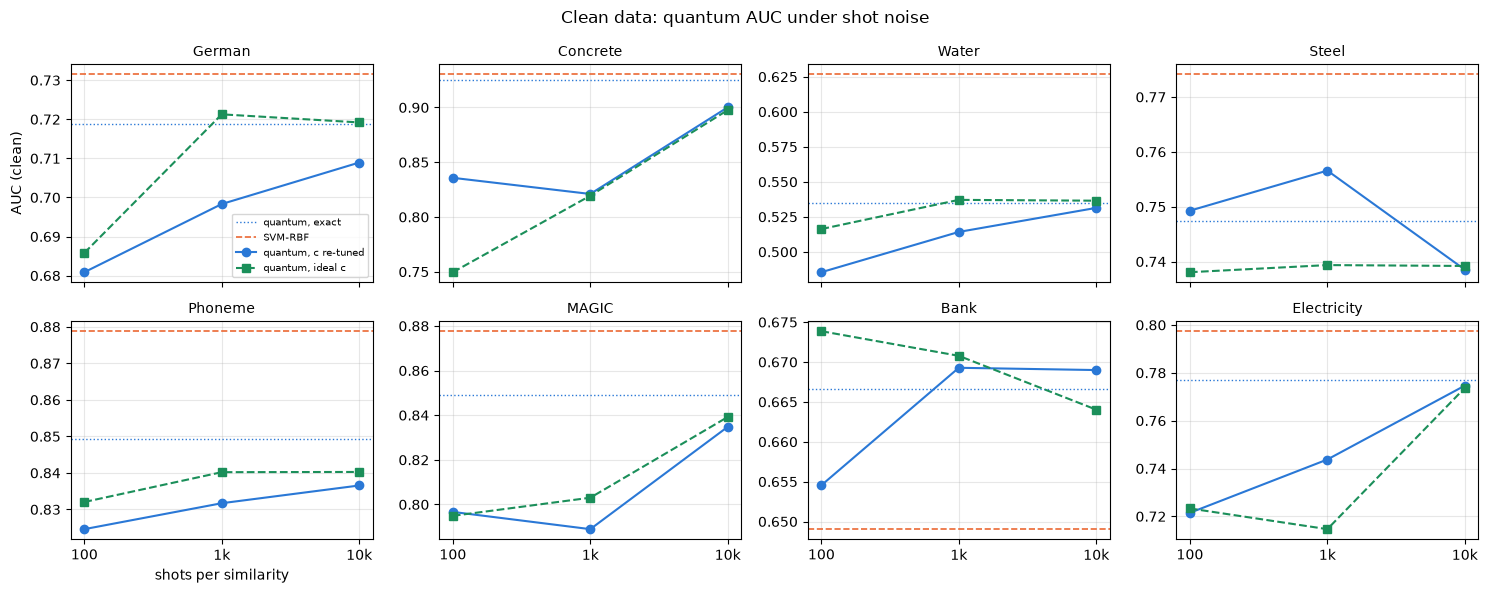

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(15, 6), sharex=True)
for ax, d in zip(axes.ravel(), DATASETS):
    g = tab.loc[d].loc["clean"]
    ax.axhline(g.loc["quantum (c re-tuned)", "exact"], color="#2a78d6", ls=":", lw=1, label="quantum, exact")
    ax.axhline(g.loc["quantum (c re-tuned)", "SVM-RBF"], color="#eb6834", ls="--", lw=1.2, label="SVM-RBF")
    ax.plot(SHOTS, g.loc["quantum (c re-tuned)", SHOTS], "o-", color="#2a78d6", label="quantum, c re-tuned")
    ax.plot(SHOTS, g.loc["quantum (ideal c)", SHOTS], "s--", color="#1b8f5a", label="quantum, ideal c")
    ax.set_xscale("log"); ax.set_xticks(SHOTS); ax.set_xticklabels(["100", "1k", "10k"]); ax.minorticks_off()
    ax.set_title(SHORT[d], fontsize=10); ax.grid(alpha=0.3)
axes[0, 0].legend(fontsize=7); axes[1, 0].set_xlabel("shots per similarity"); axes[0, 0].set_ylabel("AUC (clean)")
fig.suptitle("Clean data: quantum AUC under shot noise"); plt.tight_layout()
plt.savefig(ANALYSIS / "fig_shot_noise.png", dpi=150); plt.show()